# IAM training data: a simple overview

This notebook answers: **How much text do we have? Which letters, digits and symbols occur? How long are the lines and words?**

We use the existing, verified **IAM training export** used for our handwriting-aware tokenizer work. It contains 5,694 lines in this project's training split. These numbers describe this split, not the entire IAM database.

The notebook reads ground-truth transcriptions and recorded image dimensions. It does not open image files or run the recognizer, connected-component labeling (CCL), or tokenizer training. Character frequency tells us what is written; CCL is needed to study how the handwriting connects.

Run all cells with the `dtlr-poc` Python environment (pandas and matplotlib). Inputs are read-only; the last cell saves small tables only inside `DTLR/outputs/iam-train-overview/`.


In [1]:
from pathlib import Path
from collections import Counter
import hashlib
import json
import os
import unicodedata

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# These are the existing IAM train exports, not the raw dataset directory.
if os.name == "nt":
    REPO = Path("//wsl.localhost/Ubuntu/home/artellisys/DTLR")
    IAM_TRAIN = Path("//wsl.localhost/Ubuntu/home/artellisys/dtlr-output/iam-train-full")
else:
    REPO = Path("/home/artellisys/DTLR")
    IAM_TRAIN = Path("/home/artellisys/dtlr-output/iam-train-full")

SELECTION_PATH = IAM_TRAIN / "selection.json"
TRANSCRIPTIONS_PATH = IAM_TRAIN / "detections.jsonl"
OUTPUT_DIR = REPO / "outputs/iam-train-overview"
assert REPO.is_dir(), f"DTLR repository not found: {REPO}"
assert OUTPUT_DIR.resolve().is_relative_to(REPO.resolve())

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 55)

## 1. Load the verified training transcriptions

We check file hashes, IAM/train metadata, line IDs, and transcription hashes against the frozen selection. Text is kept exactly as recorded: case, spaces and punctuation all count. We check NFC normalization without changing the text.


In [2]:
def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

expected_hashes = {
    "selection": "7893dfba4febe6df99cf0bdb0c74fabe7b736d2a6af05033d8638b90455bc1c2",
    "transcriptions": "5e68b4c2ef1db15b5d1776ba1d4b7696ba9289f81dd4dd018598dd7d6aea2b32",
}
assert sha256_file(SELECTION_PATH) == expected_hashes["selection"], "Selection file changed"
assert sha256_file(TRANSCRIPTIONS_PATH) == expected_hashes["transcriptions"], "Export file changed"
selection = json.loads(SELECTION_PATH.read_text(encoding="utf-8"))
assert selection["schema_version"] == "dtlr.iam-selection.v1"
assert (selection["dataset"], selection["split"]) == ("IAM", "train")

# Keep only ground-truth text and image metadata; discard prediction arrays.
rows = []
with TRANSCRIPTIONS_PATH.open(encoding="utf-8") as handle:
    for raw in handle:
        if not raw.strip():
            continue
        record = json.loads(raw)
        assert record["schema_version"] == "dtlr.detections.v1"
        assert (record["dataset"], record["split"]) == ("IAM", "train")
        rows.append({"line_id": record["line_id"], "text": record["transcription"],
                     "image_width": record["image_width"], "image_height": record["image_height"]})

assert len(rows) == selection["requested_count"] == len(selection["lines"])
assert len({row["line_id"] for row in rows}) == len(rows)
for row, selected in zip(rows, selection["lines"]):
    assert row["line_id"] == selected["id"]
    assert hashlib.sha256(row["text"].encode("utf-8")).hexdigest() == selected["transcription_sha256"]
    assert unicodedata.normalize("NFC", row["text"]) == row["text"]

lines = pd.DataFrame(rows)
assert (lines[["image_width", "image_height"]] > 0).all().all()
print(f"Verified {len(lines):,} IAM training lines.")


Verified 5,694 IAM training lines.


## 2. How much text is there?

A **character** includes a space or punctuation mark. A **whitespace token** is a chunk from `text.split()`: it may be a word, a number, or standalone punctuation. It is not a cleaned linguistic word.


In [3]:
texts = lines["text"].tolist()
characters = Counter(character for text in texts for character in text)
whitespace_tokens = [token for text in texts for token in text.split()]
total_characters = sum(characters.values())
lines["characters"] = lines["text"].str.len()
lines["whitespace_tokens"] = lines["text"].map(lambda text: len(text.split()))

summary = {
    "Training lines": len(lines),
    "Characters (including whitespace)": total_characters,
    "Characters (excluding whitespace)": sum(n for c, n in characters.items() if not c.isspace()),
    "Unique characters": len(characters),
    "Whitespace tokens": len(whitespace_tokens),
    "Unique whitespace tokens (case-sensitive)": len(set(whitespace_tokens)),
    "Average characters per line": round(lines["characters"].mean(), 2),
    "Average whitespace tokens per line": round(lines["whitespace_tokens"].mean(), 2),
}
display(pd.DataFrame(summary.items(), columns=["Measure", "Value"]))


,Measure,Value
0,Training lines,5694.00
1,Characters (including whitespace),241876.00
2,Characters (excluding whitespace),204053.00
3,Unique characters,79.00
4,Whitespace tokens,43517.00
5,Unique whitespace tokens (case-sensitive),8733.00
6,Average characters per line,42.48
7,Average whitespace tokens per line,7.64


## 3. Which characters and symbols occur?

Each character gets its own count: `A` and `a` are different. Categories below use Unicode properties. Symbols include punctuation such as commas and brackets. `<SPACE>` makes the otherwise invisible space easy to see.


In [4]:
def character_label(character):
    labels = {" ": "<SPACE>", "\t": "<TAB>", "\n": "<NEWLINE>"}
    return labels.get(character, character)

def character_group(character):
    if character.isspace():
        return "Whitespace"
    if character.isalpha():
        return "Letters"
    if character.isdigit():
        return "Digits"
    return "Punctuation / symbols"

character_table = pd.DataFrame([
    {"character": character_label(c), "codepoint": f"U+{ord(c):04X}",
     "unicode_name": unicodedata.name(c, "UNNAMED"), "category": character_group(c),
     "count": count, "percent_of_characters": 100 * count / total_characters,
     "lines_containing": sum(c in text for text in texts)}
    for c, count in sorted(characters.items(), key=lambda item: (-item[1], ord(item[0])))
])
category_table = character_table.groupby("category", sort=False).agg(
    unique_characters=("character", "size"), occurrences=("count", "sum")
)
category_table["percent_of_characters"] = 100 * category_table["occurrences"] / total_characters
display(category_table.round(2))

for group in ["Letters", "Digits", "Punctuation / symbols", "Whitespace"]:
    inventory = [character_label(c) for c in sorted(characters) if character_group(c) == group]
    print(f"{group} ({len(inventory)} unique): {' '.join(inventory)}")


,unique_characters,occurrences,percent_of_characters
category,,,
Whitespace,1,37823,15.64
Letters,52,196231,81.13
Punctuation / symbols,16,6938,2.87
Digits,10,884,0.37


Letters (52 unique): A B C D E F G H I J K L M N O P Q R S T U V W X Y Z a b c d e f g h i j k l m n o p q r s t u v w x y z
Digits (10 unique): 0 1 2 3 4 5 6 7 8 9
Punctuation / symbols (16 unique): ! " # & ' ( ) * + , - . / : ; ?
Whitespace (1 unique): <SPACE>


In [5]:
# The complete alphabet, including rare characters.
display(character_table.round({"percent_of_characters": 3}))

,character,codepoint,unicode_name,category,count,percent_of_characters,lines_containing
0,<SPACE>,U+0020,SPACE,Whitespace,37823,15.637,5640
1,e,U+0065,LATIN SMALL LETTER E,Letters,24822,10.262,5600
2,t,U+0074,LATIN SMALL LETTER T,Letters,17487,7.230,5403
3,a,U+0061,LATIN SMALL LETTER A,Letters,15482,6.401,5375
4,o,U+006F,LATIN SMALL LETTER O,Letters,14115,5.836,5255
5,n,U+006E,LATIN SMALL LETTER N,Letters,13707,5.667,5241
6,i,U+0069,LATIN SMALL LETTER I,Letters,13354,5.521,5178
7,r,U+0072,LATIN SMALL LETTER R,Letters,12184,5.037,5105
8,s,U+0073,LATIN SMALL LETTER S,Letters,12021,4.970,5032
9,h,U+0068,LATIN SMALL LETTER H,Letters,10558,4.365,4854


### Punctuation and symbols in detail

The table shows both the total occurrences and the number of lines containing each symbol. A symbol repeated twice in one line contributes two occurrences but one line.


,character,codepoint,unicode_name,count,percent_of_characters,lines_containing
21,.,U+002E,FULL STOP,2583,1.068,2212
22,",",U+002C,COMMA,2213,0.915,1756
26,-,U+002D,HYPHEN-MINUS,638,0.264,568
29,',U+0027,APOSTROPHE,596,0.246,485
32,"""",U+0022,QUOTATION MARK,433,0.179,327
52,!,U+0021,EXCLAMATION MARK,91,0.038,78
57,:,U+003A,COLON,80,0.033,80
59,;,U+003B,SEMICOLON,68,0.028,64
64,(,U+0028,LEFT PARENTHESIS,54,0.022,54
68,#,U+0023,NUMBER SIGN,47,0.019,47


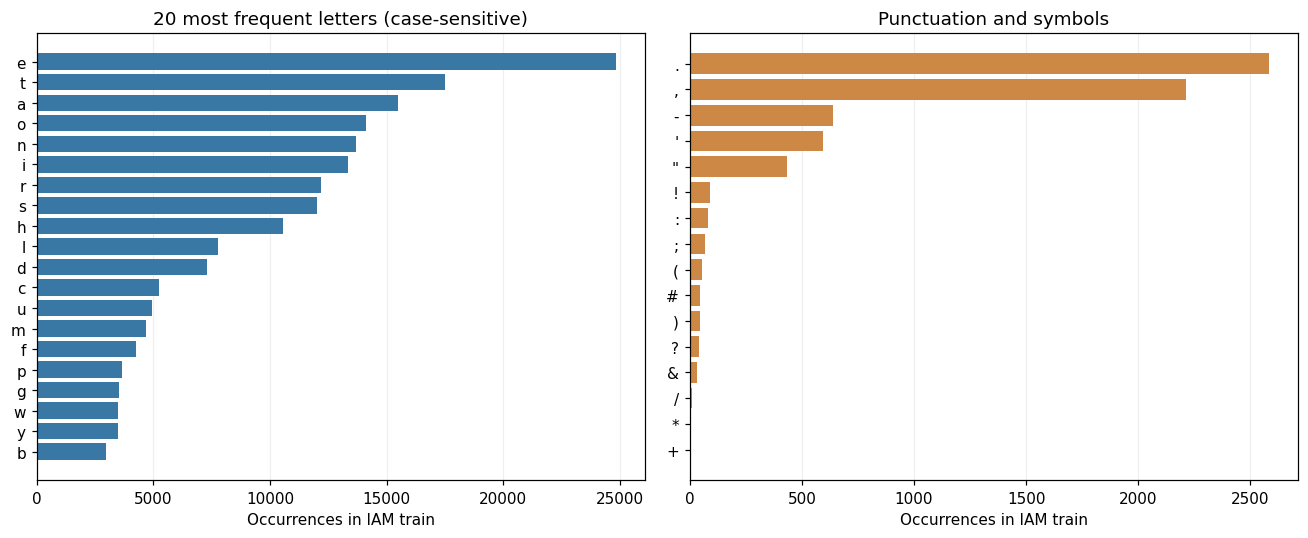

In [6]:
symbol_table = character_table[character_table["category"] == "Punctuation / symbols"].copy()
display(symbol_table.drop(columns="category").round({"percent_of_characters": 3}))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
letter_table = character_table[character_table["category"] == "Letters"].head(20)
axes[0].barh(letter_table["character"][::-1], letter_table["count"][::-1], color="#3977a5")
axes[0].set_title("20 most frequent letters (case-sensitive)")
axes[0].set_xlabel("Occurrences in IAM train")
axes[1].barh(symbol_table["character"][::-1], symbol_table["count"][::-1], color="#cc8844")
axes[1].set_title("Punctuation and symbols")
axes[1].set_xlabel("Occurrences in IAM train")
for axis in axes:
    axis.grid(axis="x", alpha=0.2)
    axis.set_axisbelow(True)
fig.tight_layout()
plt.show()

## 4. How long are lines and whitespace tokens?

The plots help estimate typical sequence lengths. These are raw text lengths, before bigram, BPE or Unigram tokenization.


,count,mean,std,min,50%,90%,95%,max
Characters per line,5694.0,42.48,9.94,1.0,43.0,54.0,58.0,77.0
Whitespace tokens per line,5694.0,7.64,2.18,1.0,8.0,10.0,11.0,16.0


,count,mean,std,min,50%,90%,95%,max
Token characters,43517.0,4.69,2.69,1.0,4.0,9.0,10.0,20.0


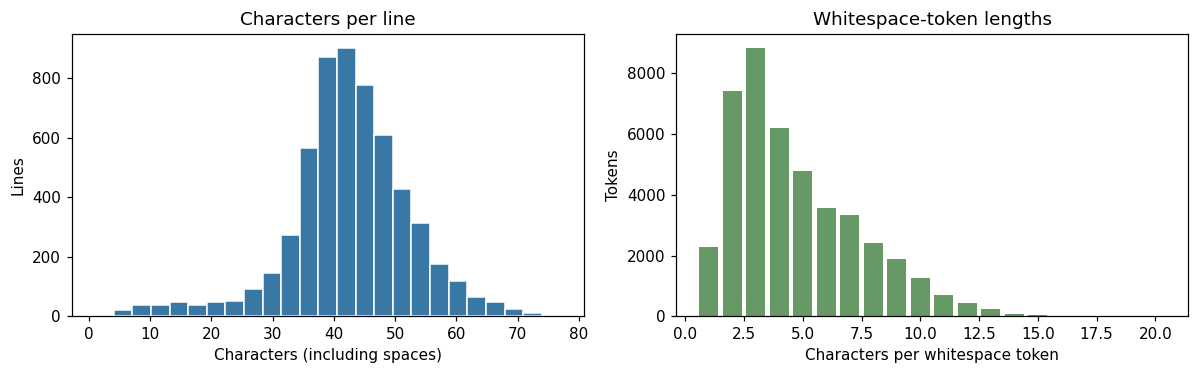

In [7]:
token_lengths = pd.Series([len(token) for token in whitespace_tokens], name="Token characters")
length_summary = pd.DataFrame({
    "Characters per line": lines["characters"],
    "Whitespace tokens per line": lines["whitespace_tokens"],
}).describe(percentiles=[0.5, 0.9, 0.95]).T
# Token lengths have a different number of observations, so summarize separately.
display(length_summary.round(2))
display(token_lengths.describe(percentiles=[0.5, 0.9, 0.95]).to_frame().T.round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(lines["characters"], bins=25, color="#3977a5", edgecolor="white")
axes[0].set(title="Characters per line", xlabel="Characters (including spaces)", ylabel="Lines")
length_counts = token_lengths.value_counts().sort_index()
axes[1].bar(length_counts.index, length_counts.values, color="#669966")
axes[1].set(title="Whitespace-token lengths", xlabel="Characters per whitespace token", ylabel="Tokens")
fig.tight_layout()
plt.show()


## 5. Common text and image dimensions

The frequent-token table keeps original case and punctuation. Image dimensions come from the export metadata; they describe the images supplied to the earlier pipeline, not necessarily the original IAM scans.


In [8]:
common_tokens = pd.DataFrame(Counter(whitespace_tokens).most_common(15), columns=["Whitespace token", "Count"])
display(common_tokens)
display(lines[["image_width", "image_height"]].describe(percentiles=[0.5, 0.9]).round(1))


,Whitespace token,Count
0,the,2571
1,of,1363
2,to,1168
3,a,982
4,and,975
5,in,810
6,is,520
7,that,477
8,"""",410
9,for,391


,image_width,image_height
count,5694.0,5694.0
mean,1735.1,121.8
std,288.1,31.8
min,147.0,44.0
50%,1793.0,119.0
90%,1948.0,165.0
max,2301.0,271.0


## 6. What does this mean for our tokenizers?

A tokenizer needs singleton characters for **every character in its intended input alphabet**, including rare symbols. The empty CTC blank is a model class; it is not a character written in the transcription.

Compare the observed training alphabet with the frozen handwriting-bigram artifact below. That artifact's singleton layer was built from adjacent-pair evidence, which can miss isolated symbols. This is an alphabet coverage check; it does not measure recognition accuracy or handwriting connectivity.


In [9]:
frozen_path = REPO / "poc/frozen/iam-english-handwriting-bigram-v1.json"
assert sha256_file(frozen_path) == "2fbb81479211454d8ad028d8af76eb26e76b75b80408a1a1e1f4efa15ab26a92"
frozen = json.loads(frozen_path.read_text(encoding="utf-8"))
frozen_singletons = {token for token in frozen["vocab"] if len(token) == 1}
missing = sorted(set(characters) - frozen_singletons)
print(f"Observed IAM train alphabet: {len(characters)} characters")
print(f"Frozen bigram singleton alphabet: {len(frozen_singletons)} characters")
print(f"IAM train lines containing a missing symbol: {sum(any(c in text for c in missing) for text in texts)}")
display(pd.DataFrame([
    {"Missing character": character_label(c), "Occurrences": characters[c],
     "Lines containing": sum(c in text for text in texts)} for c in missing
]))


Observed IAM train alphabet: 79 characters
Frozen bigram singleton alphabet: 76 characters
IAM train lines containing a missing symbol: 133


,Missing character,Occurrences,Lines containing
0,#,47,47
1,&,32,32
2,(,54,54


## 7. Save the small analysis tables

Outputs stay inside this repository's ignored `outputs` directory. The frozen model and input data are unchanged. We save aggregate tables, not full line transcriptions.


In [10]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
character_table.to_csv(OUTPUT_DIR / "character_inventory.csv", index=False)
symbol_table.to_csv(OUTPUT_DIR / "symbol_inventory.csv", index=False)
analysis_summary = {
    "dataset": "IAM", "split": "train", "scope": "existing complete project training export",
    "counts": summary,
    "character_categories": category_table.reset_index().to_dict(orient="records"),
    "missing_from_frozen_bigram_singletons": {c: characters[c] for c in missing},
    "source_paths": {"selection": str(SELECTION_PATH), "transcriptions": str(TRANSCRIPTIONS_PATH)},
    "source_sha256": expected_hashes,
}
(OUTPUT_DIR / "summary.json").write_text(
    json.dumps(analysis_summary, ensure_ascii=False, indent=2) + "\n", encoding="utf-8"
)
print(f"Saved character_inventory.csv, symbol_inventory.csv and summary.json to {OUTPUT_DIR}")


Saved character_inventory.csv, symbol_inventory.csv and summary.json to /home/artellisys/DTLR/outputs/iam-train-overview


### Takeaway

Use the character inventory to check alphabet coverage and the length distributions to understand typical text sequences. Frequency does not tell us whether neighboring letters share an ink component. Our handwriting-aware tokenizer work adds that image evidence separately.

These are descriptive training statistics. They do not establish performance on held-out IAM data or other datasets.
